# GAMERA + Gammapy Jupyter Notebook Tutorial


## Overview

This notebook tutorial teaches users how to combine GAMERA — an open-source C++/Python for spectral modelling of non-thermally emitting astrophysical sources — with the Gammapy analysis framework to model and fit high-energy source spectra. 

GAMERA's Python module is called **`gappa`** (built via SWIG); all API calls in this tutorial use `import gappa`.



## Section 1 — Environment Setup & Building gappa


1. **Activate your existing gammapy environment**

```bash
conda activate gammapy-2.1
```
 (if you don't have one, create it as)

```bash
curl -O https://gammapy.org/download/install/gammapy-2.1-environment.yml
conda env create -f gammapy-2.1-environment.yaml
conda activate gammapy-2.1
gammapy download notebooks
gammapy download datasets
conda env config vars set GAMMAPY_DATA=$PWD/gammapy-datasets/2.1
conda activate gammapy-2.1


2. **Install system dependencies**

   ```bash
   # Linux (Ubuntu)
   sudo apt install libgsl23 libgsl-dev swig python-dev pkg-config
   # macOS (Homebrew)
   brew install gsl swig  pkg-config
   ```

specific Mac troubleshooting can be found in the [GAMERA docu](https://libgamera.github.io/GAMERA/docs/download_installation)

3. **Clone GAMERA and build the shared library + Python bindings**

   ```bash
   git clone https://github.com/libgamera/GAMERA.git
   cd GAMERA
   make all          # builds lib/libgamera.so, lib/_gappa.so, lib/gappa.py
   ```

4. **Make `gappa` importable — add `lib/` to `PYTHONPATH`**

   ```bash
   export PYTHONPATH=$(pwd)/lib:$PYTHONPATH
   # Or add this line to your ~/.bashrc / conda activation script
   ```


5. **Verify**

   ```python
   import gappa
   import gammapy 
   fr = gappa.Radiation()
   print("gappa loaded — Radiation object:", fr)
   ```





6. **Interactive plots**

    This notebook uses interactive plots through `ipywidgets`. You might have to install it as
   `pip install ipywidgets`

**Note that if you already have a jupyter notebook instance running, you will have to re-start it after installing GAMERA and adding it to the PYTHONPATH**

**References:**

- Hahn, J. (2015) — GAMERA paper; [ascl:2203.007](https://ascl.net/2203.007)
- GAMERA documentation: [libgamera.github.io/GAMERA](http://libgamera.github.io/GAMERA/)
- GAMERA repository: [github.com/libgamera/GAMERA](https://github.com/libgamera/GAMERA)
- Gammapy documentation: [docs.gammapy.org](https://docs.gammapy.org)


## A note on units
Units in GAMERA are mostly in cgs, with several exceptions that are meaningful in the astrophysical context.

    times are in years, except for particle escape time scales
    lengths are in parsecs
    when retrieving SEDs, for convenience the units are
        erg / s / cm2 vs TeV for radiation flux SEDs
        erg / s vs. TeV for luminosity SEDs (i.e. when the distance to the source is not set)
        erg vs. TeV for particle SEDs

    (differential spectra are again in cgs units)
    gas densities are in number densities.

Also, the units of the spectrum will impact the unit of the calculated radiation spectra. For instance, if the unit of the particle spectrum is only differential in energy, i.e. 1/erg, the output radiation spectra will have the unit of a flux if a source distance is specified (see below) or differential photon count per energy and time if not.

On the other hand, if the input unit is differential also in volume, i.e. 1/erg/cm3, then also the output radiation spectrum will be. Therefore, if no distance is specified in this case, a volume photon emissivity will be calculated, i.e. d3N/dEdVdt.

## Section 2 — GAMERA basics: `Particles` and `Radiation`

GAMERA's Python interface exposes two main classes: `gappa.Particles` (evolves the particle distribution over time) and `gappa.Radiation` (computes photon emission from a given particle distribution).


In [1]:
import gappa as gp
import numpy as np
import astropy.units as u
from gammapy.maps import MapAxis
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatLogSlider, FloatSlider
%matplotlib widget

### A. Build a particle spectrum in an enviroment which does not vary with time


First we will define a convenient method to create a power-law injection spectrum in the format GAMERA likes

In [2]:

# A method to create a power-law with a cutoff which we will inject continuously
def define_injected_spectrum(index=2, 
                             E_min=0.1*u.TeV, 
                             E_max=1000*u.TeV, 
                             luminosity=1e32*u.erg/u.s, 
                             E_cut=100*u.TeV,
                             Nbins=50):
    "A power-law with an exponential cutoff"
    energy_electrons = MapAxis.from_energy_bounds(energy_min=E_min, energy_max=E_max, nbin=Nbins)
    exp_cutoff = np.exp(-(energy_electrons.center.to('erg')/E_cut.to('erg')).value)
    power_law = (energy_electrons.center.to_value('erg') ** -index)*exp_cutoff

    # Normalize to total power (this is not really needed but we use it for the plot)
    fu = gp.Utils()
    integral = fu.Integrate(list(zip(energy_electrons.center.to_value('erg'), power_law * energy_electrons.center.to_value('erg'))))
    power_law *= luminosity.to_value('erg s-1') / integral 
    #################################################################################

    
    # Bundle together in the way GAMERA wants
    power_law_spectrum = np.array(list(zip(energy_electrons.center.to_value('erg'), power_law)))

    return power_law_spectrum




Then we can visualize how these continuously injected particles evolve under a magnetic field

In [4]:
def evolve_in_magnetic_field(electron_spectrum, age, B):

    fp = gp.Particles()
    #fp.ToggleQuietMode() # Commented now but useful
    fp.SetBField(B.to_value('G'))
    fp.SetAge(age.to_value('yr'))
    fp.SetCustomInjectionSpectrum(electron_spectrum)

    
    # Because B doesn't change in time, we can use the semi-analytical method  
    fp.SetSolverMethod(1)

    # Evolve and get
    fp.CalculateElectronSpectrum()
    sp = np.array(fp.GetParticleSpectrum())  # returns diff. spectrum: E(erg) vs dN/dE (1/erg)
    return sp



def plot_evolved_particles(B_uG=12, age_kyr=10):
    power_law_spectrum = define_injected_spectrum()
    B = B_uG*u.uG
    age = age_kyr*u.kyr

    sed = evolve_in_magnetic_field(power_law_spectrum, age, B)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(power_law_spectrum[:,0], age.to_value('s')*power_law_spectrum[:,1], ls='--', color='k', label='injected x age', lw=2)
    ax.loglog(sed[:,0],  sed[:,1],  label="cooled", ls="-", lw=2, color='blue')
    ax.set_xlim(0.8, 1e3)    # erg
    ax.set_ylim(1e37, 1e45)   # adjust to your source
    ax.set_xlabel("Energy (erg )")
    ax.set_ylabel(r"$dN/dE$ (erg$^{-1}$)")
    ax.set_title(f"Electron spectrum —  B={B_uG:.1f} µG, age={age_kyr:.0f} kyr")
    ax.legend()
    plt.show()

# plot_evolved_particles()
interact(
    plot_evolved_particles,
    B_uG      = FloatLogSlider(value=10,  base=10, min=-1, max=4,  step=0.1, description="B (µG)",continuous_update=False),
    age_kyr   = FloatLogSlider(value=10,   base=10, min=-2, max=4,  step=0.1, description="Age (kyr)",continuous_update=False),
)

interactive(children=(FloatLogSlider(value=10.0, continuous_update=False, description='B (µG)', min=-1.0), Flo…

<function __main__.plot_evolved_particles(B_uG=12, age_kyr=10)>

And a combination of magnetic field and radiation field

In [5]:
def evolve_in_magnetic_field_and_radiation_field(electron_spectrum, age, B, T=2.7*u.K, edens= 0.26*u.Unit("eV cm-3")):

    fp = gp.Particles()
    fp.ToggleQuietMode() # Commented now but useful
    fp.SetSolverMethod(1) # We can use the semi-analytical method because B doesn't change in time
    
    fp.SetBField(B.to_value('G'))

    ##### this is the only difference wrt to before! ########################
    # set the fields in the Radiation object
    fp.AddThermalTargetPhotons(T.to_value('K'),edens.to_value('erg cm-3'),500)
    ##########################################################################
    fp.SetAge(age.to_value('yr'))

    fp.SetCustomInjectionSpectrum(electron_spectrum)
        
    fp.CalculateElectronSpectrum()
    sp = np.array(fp.GetParticleSpectrum())  # returns diff. spectrum: E(erg) vs dN/dE (1/erg)
    return sp

def plot_evolved_particles(B_uG=1.0, age_kyr=10, T_K=2.6, edens_eVcc=0.26):
    power_law_spectrum = define_injected_spectrum()
    B = B_uG*u.uG
    age = age_kyr*u.kyr
    T = T_K*u.K
    edens = edens_eVcc*u.Unit("eV cm-3")

    sed = evolve_in_magnetic_field_and_radiation_field(power_law_spectrum, age, B, T, edens)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(power_law_spectrum[:,0], age.to_value('s')*power_law_spectrum[:,1], ls='--', color='k', label='injected x age', lw=2)
    ax.loglog(sed[:,0],  sed[:,1],  label="cooled", ls="-", lw=2, color='blue')
    ax.set_xlim(0.8, 1e3)    # erg
    ax.set_ylim(1e37, 1e45)   # adjust to your source
    ax.set_xlabel("Energy (erg)")
    ax.set_ylabel(r"$dN/dE$ (erg$^{-1}$)")
    ax.set_title(f"Electron spectrum —  B={B_uG:.1f} µG, age={age_kyr:.0f} kyr")
    ax.legend()
    plt.show()


interact(
    plot_evolved_particles,
    B_uG      = FloatLogSlider(value=10,  base=10, min=-1, max=4,  step=0.1, description="B (µG)",continuous_update=False),
    age_kyr   = FloatLogSlider(value=10,   base=10, min=-2, max=4,  step=0.1, description="Age (kyr)",continuous_update=False),
    T_K      = FloatLogSlider(value=2.7,  base=10, min=-1, max=4,  step=0.1, description="T (K)",continuous_update=False),
    edens_eVcc   = FloatSlider(value=0.26,  min=0.1, max=100,  step=0.1, description="u$_{rad}$(eV/cc)",continuous_update=False),
)

interactive(children=(FloatLogSlider(value=10.0, continuous_update=False, description='B (µG)', min=-1.0), Flo…

<function __main__.plot_evolved_particles(B_uG=1.0, age_kyr=10, T_K=2.6, edens_eVcc=0.26)>

## B. Pass the spectrum to `Radiation` and set up the source distance

In [6]:
def radiate_in_magnetic_field_and_radiation_field(age, B, T=2.7*u.K, edens= 0.26*u.Unit("eV cm-3"), distance=5*u.kpc):
   # Define photon energies we want
    photon_energies = np.logspace(-16,4,200)*u.TeV
    power_law_spectrum = define_injected_spectrum()
    evolved_electrons = evolve_in_magnetic_field_and_radiation_field(power_law_spectrum, age, B, T, edens)
  
    fr = gp.Radiation()
    fr.ToggleQuietMode()
    fr.SetElectrons(evolved_electrons)
    fr.AddThermalTargetPhotons(T.to_value('K'),edens.to_value('erg cm-3'),500)
    fr.SetDistance(distance.to_value('pc'))
    fr.SetBField(B.to_value('G'))


    # compute the spectrum on the points given by the data
    fr.CalculateDifferentialPhotonSpectrum(photon_energies.to_value('erg'))
    sync_sed  = np.asarray(fr.GetSynchrotronSED())  # [[E/erg], [E^2 dN/dE/dA/dt]]
    ic_sed    = np.asarray(fr.GetICSED())
    total_sed = np.asarray(fr.GetTotalSED())
    
    return evolved_electrons, sync_sed, ic_sed, total_sed


def plot_all(B_uG=1.0, age_kyr=10, T_K=2.6, edens_eVcc=0.26, distance_kpc=5):
    B = B_uG*u.uG
    age = age_kyr*u.kyr
    T = T_K*u.K
    edens = edens_eVcc*u.Unit("eV cm-3")

    # for the plot
    power_law_spectrum = define_injected_spectrum()

    evolved_electrons, sync_sed, ic_sed, total_sed = radiate_in_magnetic_field_and_radiation_field(age, B, T, edens,distance=distance_kpc*u.kpc)
    
    fig, axes = plt.subplots(1,2,figsize=(12, 5))

    ax = axes[0]
    ax.loglog(power_law_spectrum[:,0], age.to_value('s')*power_law_spectrum[:,1], ls='--', color='k', label='injected x age', lw=2)
    ax.loglog(evolved_electrons[:,0],  evolved_electrons[:,1],  label="cooled", ls="-", lw=2, color='blue')
    ax.set_xlim(0.8, 1e3)    # erg
    ax.set_ylim(1e37, 1e45)   # adjust to your source
    ax.set_xlabel("Energy (erg)")
    ax.set_ylabel(r"$dN/dE$ (erg$^{-1}$)")
    ax.set_title(f"Electron spectrum —  B={B_uG:.1f} µG, age={age_kyr:.0f} kyr")
    ax.legend()

    ax = axes[1]
    ax.loglog(sync_sed[:,0],  sync_sed[:,1],  label="synch", ls="-", lw=2, color='blue')
    ax.loglog(ic_sed[:,0],  ic_sed[:,1],  label="IC", ls="-", lw=2, color='gold')
    ax.loglog(total_sed[:,0], total_sed[:,1], ls='--', color='k', label='total', lw=2)

    ax.set_ylim(1e-18,1e-14)   # adjust to your source
    ax.set_xlabel("Energy (TeV)")
    ax.set_ylabel(r"$E^2 dN/dE$ (erg cm$^{-2}$ s$^{-1}$)")
    ax.set_title(f"Photon SED —  B={B_uG:.1f} µG, age={age_kyr:.0f} kyr")
    ax.legend()
    plt.show()


interact(
    plot_all,
    B_uG      = FloatLogSlider(value=10,  base=10, min=-1, max=4,  step=0.1, description="B (µG)",continuous_update=False),
    age_kyr   = FloatLogSlider(value=10,   base=10, min=-2, max=4,  step=0.1, description="Age (kyr)",continuous_update=False),
    T_K      = FloatLogSlider(value=2.7,  base=10, min=-1, max=4,  step=0.1, description="T (K)",continuous_update=False),
    edens_eVcc   = FloatSlider(value=0.26,  min=0.1, max=100,  step=0.1, description="u$_{rad}$(eV/cc)",continuous_update=False),
)

interactive(children=(FloatLogSlider(value=10.0, continuous_update=False, description='B (µG)', min=-1.0), Flo…

<function __main__.plot_all(B_uG=1.0, age_kyr=10, T_K=2.6, edens_eVcc=0.26, distance_kpc=5)>

### C.Time-varying 
The examples above all had continuous injection and an environment which does not change with time. GAMERA can handle time-varying environments, a detailed tutorial and information can be found in the [gamera docu](https://libgamera.github.io/GAMERA/docs/time_dependent_modeling)

Basically one just has to change the `SetX()` inputs (e.g. `fr.SetBField(B.to_value('G'))` by lists like `list(zip(time_steps,b))`

Try it! (exercise A)

### D. Hadronic case
Works the same way only we have to use `fp.CalculateProtonSpectrum()`. We will also now set the density for pp interactions (note that the density can also be relevant for electrons)

In [7]:
def evolve_protons_in_magnetic_field_and_radiation_field_and_density(electron_spectrum, age, B, n, T=2.7*u.K, edens= 0.26*u.Unit("eV cm-3")):

    fp = gp.Particles()
    fp.ToggleQuietMode() # Commented now but useful to have off
    fp.SetSolverMethod(1) # We can use the semi-analytical method because B doesn't change in time
    
    fp.SetBField(B.to_value('G'))
    ##### NEW ################################################################
    fp.SetAmbientDensity(n.to_value('cm-3'))
    ##########################################################################
    
    # set the fields in the Radiation object
    fp.AddThermalTargetPhotons(T.to_value('K'),edens.to_value('erg cm-3'),500)
    fp.SetAge(age.to_value('yr'))

    fp.SetCustomInjectionSpectrum(electron_spectrum)

    ##### NEW ################################################################
    fp.CalculateProtonSpectrum()
    ##########################################################################

    sp = np.array(fp.GetParticleSpectrum())  # returns diff. spectrum: E(erg) vs dN/dE (1/erg)
    return sp

def radiate_in_magnetic_field_and_radiation_field_and_density(age, B, n,T=2.7*u.K, edens= 0.26*u.Unit("eV cm-3"), distance=5*u.kpc):
   # Define photon energies we want
    photon_energies = np.logspace(-16,4,200)*u.TeV
    power_law_spectrum = define_injected_spectrum()
    evolved_electrons = evolve_in_magnetic_field_and_radiation_field(power_law_spectrum, age, B, T, edens)
    evolved_protons = evolve_protons_in_magnetic_field_and_radiation_field_and_density(power_law_spectrum, age, B, n, T, edens)
    
    fr = gp.Radiation()
    fr.ToggleQuietMode()
    fr.SetElectrons(evolved_electrons)
    fr.SetProtons(evolved_protons)

    fr.AddThermalTargetPhotons(T.to_value('K'),edens.to_value('erg cm-3'),500)
    fr.SetDistance(distance.to_value('pc'))
    fr.SetBField(B.to_value('G'))
    ##### NEW ################################################################
    fr.SetAmbientDensity(n.to_value('cm-3'))
    ##########################################################################

    # compute the spectrum on the points given by the data
    fr.CalculateDifferentialPhotonSpectrum(photon_energies.to_value('erg'))
    sync_sed  = np.asarray(fr.GetSynchrotronSED())  # [[E/erg], [E^2 dN/dE/dA/dt]]
    ic_sed    = np.asarray(fr.GetICSED())
    pp_sed    = np.asarray(fr.GetPPSED()) # add pp
    total_sed = np.asarray(fr.GetTotalSED())
    
    return evolved_electrons, sync_sed, ic_sed, pp_sed,total_sed


def plot_all(B_uG=1.0, age_kyr=10, T_K=2.6, edens_eVcc=0.26, distance_kpc=5, ncc=1e3):
    B = B_uG*u.uG
    age = age_kyr*u.kyr
    T = T_K*u.K
    edens = edens_eVcc*u.Unit("eV cm-3")
    n = ncc*u.Unit("cm-3")
    
    # for the plot
    power_law_spectrum = define_injected_spectrum()

    evolved_electrons, sync_sed, ic_sed, pp_sed, total_sed = radiate_in_magnetic_field_and_radiation_field_and_density(age, B, n,T, edens,distance=distance_kpc*u.kpc)
    evolved_protons = evolve_protons_in_magnetic_field_and_radiation_field_and_density(power_law_spectrum, age, B, n, T, edens)

    fig, axes = plt.subplots(1,2,figsize=(12, 5))

    ax = axes[0]
    ax.loglog(power_law_spectrum[:,0], age.to_value('s')*power_law_spectrum[:,1], ls='--', color='k', label='injected x age', lw=2)
    ax.loglog(evolved_electrons[:,0],  evolved_electrons[:,1],  label="cooled electrons", ls="-", lw=2, color='blue')
    ax.loglog(evolved_protons[:,0],  evolved_protons[:,1],  label="cooled protons", ls="-", lw=2, color='darkred')

    ax.set_xlim(0.8, 1e3)    # erg
    ax.set_ylim(1e37, 1e45)   # adjust to your source
    ax.set_xlabel("Energy (erg)")
    ax.set_ylabel(r"$dN/dE$ (erg$^{-1}$)")
    ax.set_title(f"Particle spectrum —  B={B_uG:.1f} µG, age={age_kyr:.0f} kyr")
    ax.legend()

    ax = axes[1]
    ax.loglog(sync_sed[:,0],  sync_sed[:,1],  label="synch", ls="-", lw=2, color='blue')
    ax.loglog(ic_sed[:,0],  ic_sed[:,1],  label="IC", ls="-", lw=2, color='gold')
    ax.loglog(pp_sed[:,0],  pp_sed[:,1],  label="pp", ls="-", lw=2, color='darkred')

    ax.loglog(total_sed[:,0], total_sed[:,1], ls='--', color='k', label='total', lw=2)

    ax.set_ylim(1e-18,1e-14)   # adjust to your source
    ax.set_xlabel("Energy (TeV)")
    ax.set_ylabel(r"$E^2 dN/dE$ (erg cm$^{-2}$ s$^{-1}$)")
    ax.set_title(f"Photon SED —  B={B_uG:.1f} µG, age={age_kyr:.0f} kyr")
    ax.legend()
    plt.show()


interact(
    plot_all,
    B_uG      = FloatLogSlider(value=10,  base=10, min=-1, max=4,  step=0.1, description="B (µG)",continuous_update=False),
    age_kyr   = FloatLogSlider(value=10,   base=10, min=-2, max=4,  step=0.1, description="Age (kyr)",continuous_update=False),
    ncc   = FloatLogSlider(value=1e3, base=10, min=0, max=6,  step=0.1, description="n (cm-3)",continuous_update=False),
    T_K      = FloatLogSlider(value=2.7,  base=10, min=-1, max=4,  step=0.1, description="T (K)",continuous_update=False),
    edens_eVcc   = FloatSlider(value=0.26,  min=0.1, max=100,  step=0.1, description="u$_{rad}$(eV/cc)",continuous_update=False),
)


interactive(children=(FloatLogSlider(value=10.0, continuous_update=False, description='B (µG)', min=-1.0), Flo…

<function __main__.plot_all(B_uG=1.0, age_kyr=10, T_K=2.6, edens_eVcc=0.26, distance_kpc=5, ncc=1000.0)>

## Bonus: cooling times plot

In [8]:
# set up particle spectrum with random environmental parameters
fp = gp.Particles()
fp.AddThermalTargetPhotons(10,10*gp.eV_to_erg)
fp.SetAmbientDensity(1)
fp.SetRadius(1)
fp.SetExpansionVelocity(1e9)
fp.SetBField(1e-5)
fp.SetAge(1e5)


In [9]:

# extract the cooling time scales at energy points 'e'
e = np.logspace(-5,5,150)
total = np.array(fp.GetCoolingTimeScale(e,"sum"))
ic = np.array(fp.GetCoolingTimeScale(e,"inverse_compton"))
brems = np.array(fp.GetCoolingTimeScale(e,"bremsstrahlung"))
ad = np.array(fp.GetCoolingTimeScale(e,"adiabatic_losses"))
synch = np.array(fp.GetCoolingTimeScale(e,"synchrotron"))
ioniz = np.array(fp.GetCoolingTimeScale(e,"ionization"))



Particles::SetMembers: Time (0yrs vs {3.16881e-08,1e+100}) outside boundaries.
  -> Using values from previous time step. If you don't want this, you have to extend 
     your Lookups (Luminosity,R,V,B,N etc) or set constant values (via e.g. SetBField()). 
>> CALCULATING IC LOSS LOOKUP 
    99% done
    -> DONE!   

>> COMPUTATION OF IC LOSS LOOKUP COMPLETE 



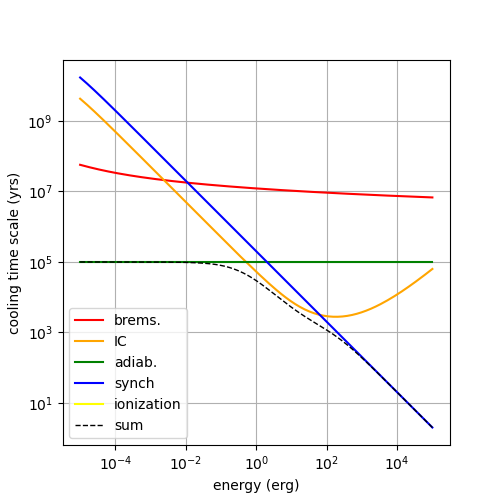

In [10]:
# make a plot
f = plt.figure(figsize=(5,5))
plt.loglog(brems[:,0],brems[:,1],c="red",label="brems.")
plt.loglog(ic[:,0],ic[:,1],c="orange",label="IC")
plt.loglog(ad[:,0],ad[:,1],c="green",label="adiab.")
plt.loglog(synch[:,0],synch[:,1],c="blue",label="synch")
plt.loglog(ioniz[:,0],ioniz[:,1],c="yellow",label="ionization")
plt.loglog(total[:,0],total[:,1],c="black",lw=1,ls="--",label="sum")
plt.xlabel("energy (erg)")
plt.ylabel("cooling time scale (yrs)")
plt.grid()
plt.legend()
plt.show()